# 04 – NetCDF vs. Zarr: file formats, chunks and loading speed

**NetCDF** (Network Common Data Form, Unidata) is the classic format for gridded
atmospheric data. A NetCDF-4 file is one single file (internally HDF5) that holds
the data, the coordinates and the metadata. It works very well on a local disk,
but to read a small part of a file stored in the cloud, you usually have to
download the whole file first.

**Zarr** is a newer, "cloud-native" format. A Zarr store is a *folder* (or a
prefix in cloud object storage) where every **chunk** of the array is a separate,
compressed object, plus small JSON files with the metadata. A program can read
only the chunks it needs, directly over the internet.

In both formats the most important design choice is the **chunk shape**:
the array is cut into blocks, and a block is always read and decompressed as a
whole. So the chunk shape decides which questions can be answered quickly:

- chunks like `(1 time, all lat, all lon)` → fast **maps**, slow **time series**
- chunks like `(all time, few lat, few lon)` → fast **time series**, slow **maps**

In this notebook we test this with one year of hourly ERA5 2 m temperature over
our region (8760 × 61 × 121 values), stored in four different ways.

In [1]:
import sys
sys.path.append("../scripts")

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr

import config as cfg
from convert_formats import OUT
from helpers import COLORS, GREY, Timer, save

## 1. What does the downloaded NetCDF file look like inside?

The `encoding` attribute shows how xarray found the variable stored on disk:
its chunk shape, compression and data type.

In [2]:
ds = xr.open_dataset(cfg.ERA5_T2M_YEAR_NC)
print(ds.t2m.shape)
{k: ds.t2m.encoding.get(k) for k in ("chunksizes", "zlib", "complevel", "dtype", "contiguous")}

(8760, 61, 121)


{'chunksizes': (2920, 21, 41),
 'zlib': True,
 'complevel': 1,
 'dtype': dtype('float32'),
 'contiguous': False}

## 2. Making the copies

`scripts/convert_formats.py` writes three more copies of exactly the same data:

| Copy | Format | Chunk shape (time × lat × lon) | Compression |
|---|---|---|---|
| `netcdf_cds` | NetCDF-4 as delivered by CDS | see above | see above |
| `netcdf_contiguous` | NetCDF-4 | no chunks (one block) | none |
| `zarr_map_chunks` | Zarr v3 | 24 × 61 × 121 (one day of maps) | zstd |
| `zarr_series_chunks` | Zarr v3 | 8760 × 10 × 10 (one year, 10×10 points) | zstd |

Writing a Zarr store from xarray is one line: `ds.chunk({...}).to_zarr(path)`.

In [3]:
for name, path in OUT.items():
    print(f"{name:20s} exists: {path.exists()}   {path.relative_to(cfg.ROOT)}")

netcdf_cds           exists: True   data/raw/era5_t2m_2023.nc
netcdf_contiguous    exists: True   data/converted/t2m_contiguous.nc
zarr_map_chunks      exists: True   data/zarr/t2m_map_chunks.zarr
zarr_series_chunks   exists: True   data/zarr/t2m_series_chunks.zarr


A Zarr store is a folder. Let's look inside one. Every chunk is a small file
named after its position in the array (`t2m/c/<time>/<lat>/<lon>`), and
`zarr.json` files hold the metadata (shape, chunk shape, compression, attributes).

In [4]:
store = OUT["zarr_map_chunks"]
files = sorted(str(p.relative_to(store)) for p in store.rglob("*") if p.is_file())
data_chunks = [f for f in files if f.startswith("t2m/c/")]
print(len(files), "files in total,", len(data_chunks), "of them are chunks of t2m")
print("metadata files:", [f for f in files if f.endswith("zarr.json")])
print("first chunks  :", data_chunks[:3])

373 files in total, 365 of them are chunks of t2m
metadata files: ['latitude/zarr.json', 'longitude/zarr.json', 't2m/zarr.json', 'valid_time/zarr.json', 'zarr.json']
first chunks  : ['t2m/c/0/0/0', 't2m/c/1/0/0', 't2m/c/10/0/0']


## 3. Benchmark

`scripts/benchmark.py` times four tasks on every copy (median of 5 runs):

- **open** – open the dataset (metadata only)
- **map** – read one time step for the whole region
- **series** – read the full year at one grid point (Ankara)
- **monthly** – compute 12 monthly means (reads all data)

The numbers are "warm cache" timings on a laptop SSD: after the first run Linux
keeps the files in memory, so we mainly measure decompression and copying, not
the disk itself.

In [5]:
bench = pd.read_csv(cfg.RESULTS / "benchmark.csv")
bench

,format,size_MB,n_files,chunks (time x lat x lon),open_s,map_s,series_s,monthly_s
0,netcdf_cds,120.9545,1,2920x21x41,0.0130,0.2733,0.1004,3.4032
1,netcdf_contiguous,258.7225,1,contiguous,0.0047,0.0063,0.0206,0.1971
2,zarr_map_chunks,164.6029,373,24x61x121,0.0129,0.0147,0.1854,0.3240
3,zarr_series_chunks,173.6489,99,8760x10x10,0.0107,0.1014,0.0172,1.3070


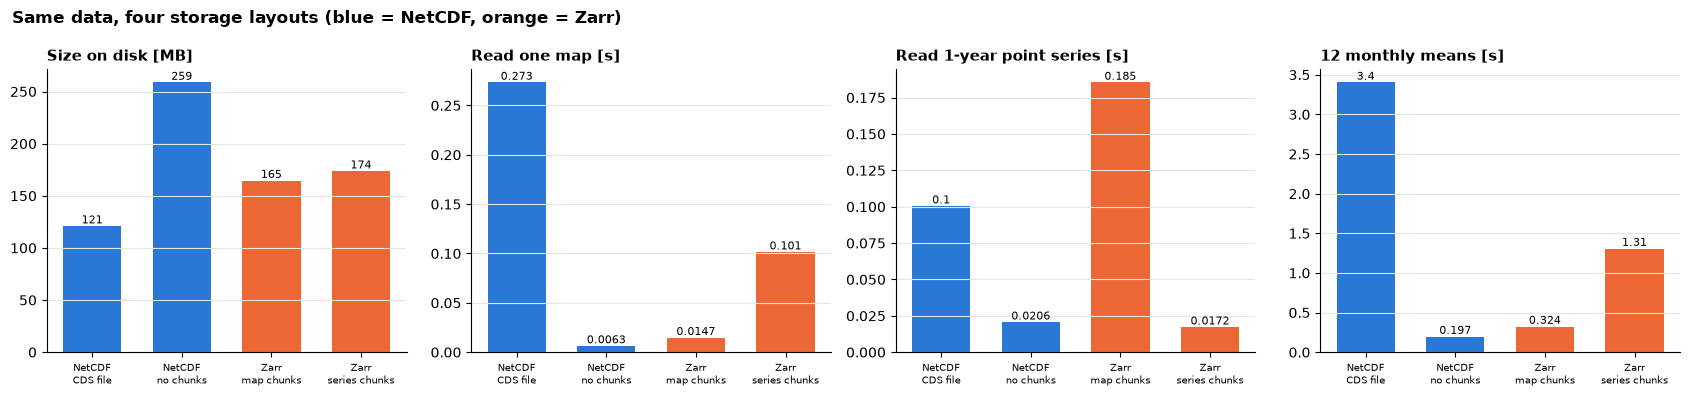

In [6]:
labels = {"netcdf_cds": "NetCDF\nCDS file", "netcdf_contiguous": "NetCDF\nno chunks",
          "zarr_map_chunks": "Zarr\nmap chunks", "zarr_series_chunks": "Zarr\nseries chunks"}
x = [labels[f] for f in bench.format]
colors = [COLORS[0], COLORS[0], COLORS[1], COLORS[1]]

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col, title in zip(axes, ["size_MB", "map_s", "series_s", "monthly_s"],
                          ["Size on disk [MB]", "Read one map [s]",
                           "Read 1-year point series [s]", "12 monthly means [s]"]):
    bars = ax.bar(x, bench[col], color=colors, width=0.65)
    ax.bar_label(bars, fmt="%.3g", fontsize=8)
    ax.set_title(title)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.grid(axis="x", visible=False)
fig.suptitle("Same data, four storage layouts (blue = NetCDF, orange = Zarr)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "04_benchmark.png")

### What the benchmark shows

- **The chunk shape decides the winner.** The Zarr store chunked for maps reads a
  map about 7× faster than the one chunked for time series, and the time-series
  store reads the 1-year point series about 11× faster than the map store.
- **The CDS file is chunked for neither task.** Its chunks are 2920 × 21 × 41
  (four months of a third of the region). To draw one map, xarray has to
  decompress 9 big chunks (3 × 3 in space), which is why it is the slowest for maps.
- **Compression costs time but saves space.** The CDS file (zlib) is the smallest,
  less than half the size of the uncompressed copy. On a local disk with a warm
  cache, the uncompressed NetCDF is the fastest for every task, because reading
  is mostly decompression. Over a network the situation reverses: every byte has
  to be transferred, so small compressed chunks become much more important.
- Zarr with the default zstd settings compressed this field less well than the
  CDS file (165 vs. 121 MB). Better results are possible with other codecs or a
  "shuffle" filter, but we kept the defaults.

## 4. Cloud-native Zarr: ERA5 on Google Cloud (ARCO-ERA5)

Google Research and ECMWF provide a copy of the complete ERA5 archive as public
Zarr stores (Carver et al., 2023). It can be opened directly over the internet,
without an account and without downloading files first.

In [7]:
with Timer() as t:
    arco = xr.open_zarr(cfg.ARCO_ERA5, chunks=None, consolidated=True,
                        storage_options={"token": "anon"})
print(f"opened in {t.seconds:.1f} s")
print(f"{len(arco.data_vars)} variables, dimensions {dict(arco.sizes)}")
print(f"total (uncompressed) size: {arco.nbytes / 1e15:.1f} PB")
print("chunk shape of 2m_temperature:", arco["2m_temperature"].encoding["chunks"])

opened in 4.1 s
273 variables, dimensions {'time': 1323648, 'latitude': 721, 'longitude': 1440, 'level': 37}
total (uncompressed) size: 3.7 PB
chunk shape of 2m_temperature: (1, 721, 1440)


Only the metadata was read, so opening several petabytes takes seconds.
The chunk shape is `(1, 721, 1440)`: **one hour of the whole globe per chunk**.
Reading a map should therefore be fast, and a time series slow, because every
hour of the series is in a different chunk that must be downloaded.

In [8]:
t2m = arco["2m_temperature"]
lat, lon = cfg.CITIES["Ankara"]
lat_g, lon_g = round(lat * 4) / 4, round(lon * 4) / 4   # nearest 0.25° grid point

with Timer() as t_map:
    one_map = t2m.sel(time="2023-04-09T12:00").load()
with Timer() as t_series:
    series = t2m.sel(time=slice("2023-04-09T00:00", "2023-04-10T23:00"),
                     latitude=lat_g, longitude=lon_g).load()
print(f"one global map  (1 chunk):   {t_map.seconds:5.1f} s")
print(f"48-hour series  (48 chunks): {t_series.seconds:5.1f} s")

one global map  (1 chunk):     3.0 s
48-hour series  (48 chunks):  19.9 s


The global map contains about one million values, the 48-hour series only 48,
yet the series takes several times longer. Each hour of the series lives in a
different chunk, so 48 whole global chunks have to be downloaded to keep one value
from each. This is the chunk effect from our local benchmark, but much bigger,
because every chunk has to travel over the network. All analysis-ready
ARCO-ERA5 stores use one-hour chunks, so long time series at single points are
better downloaded from CDS (or re-chunked once and stored locally).

### Is it the same data as our CDS download?

A good check: the cloud copy and the file we downloaded from CDS should give the
same values at the same point and time.

maximum difference CDS file vs. ARCO-ERA5: 0.0010 K


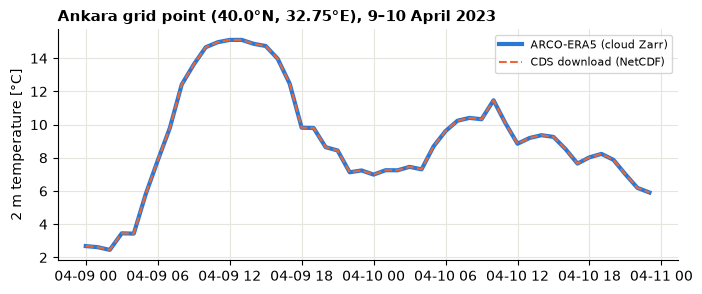

In [9]:
local = xr.open_dataset(cfg.ERA5_T2M_YEAR_NC)
tname = "valid_time" if "valid_time" in local.dims else "time"
local_series = local.t2m.sel({tname: slice("2023-04-09T00:00", "2023-04-10T23:00")}) \
                        .sel(latitude=lat_g, longitude=lon_g)
diff = abs(local_series.values - series.values).max()
print(f"maximum difference CDS file vs. ARCO-ERA5: {diff:.4f} K")

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(series.time, series - 273.15, color=COLORS[0], lw=3, label="ARCO-ERA5 (cloud Zarr)")
ax.plot(local_series[tname], local_series - 273.15, color=COLORS[1], ls="--",
        label="CDS download (NetCDF)")
ax.set_ylabel("2 m temperature [°C]")
ax.set_title(f"Ankara grid point ({lat_g}°N, {lon_g}°E), 9–10 April 2023")
ax.legend(fontsize=8)
save(fig, "04_arco_vs_cds.png")

The two sources agree within about 0.001 K, which is only rounding from the
different GRIB-to-NetCDF/Zarr conversions: it is the same ERA5 data.

## 5. Conclusions

- **Same data, different speed:** the chunk shape matters more than the format
  name. Data chunked for maps are slow for time series, and the other way round.
  Chunks should match the most common way the data will be read.
- **NetCDF** is one tidy, self-describing file that every tool can read. It is a
  good choice for downloading, archiving and sharing small to medium datasets,
  and on a local disk it is as fast as Zarr when the chunks fit the task.
- **Zarr** stores every chunk as a separate object. This is what makes it
  "cloud-native": a program can read only the chunks it needs directly from the
  cloud (ARCO-ERA5 is petabytes, but we opened it in seconds), and chunks can be
  read and written in parallel, for example with Dask.
- In the cloud the chunk effect becomes much larger than on a local disk,
  because each chunk is a separate network request.

**References:** Rew & Davis (1990) for NetCDF; Zarr specification v3
(zarr-specs.readthedocs.io); Carver et al. (2023) for ARCO-ERA5;
Hoyer & Hamman (2017) for xarray. Full list in the README.